# Practice Lab: Neural Networks for Handwritten Digit Recognition, Binary

# 实践实验：用于手写数字识别的神经网络（二分类）

In this exercise, you will use a neural network to recognize the hand-written digits zero and one.

在本练习中，您将使用神经网络来识别手写数字 0 和 1。


# Outline
- [ 1 - Packages ](#1)
- [ 2 - Neural Networks](#2)
  - [ 2.1 Problem Statement](#2.1)
  - [ 2.2 Dataset](#2.2)
  - [ 2.3 Model representation](#2.3)
  - [ 2.4 Tensorflow Model Implementation](#2.4)
    - [ Exercise 1](#ex01)
  - [ 2.5 NumPy Model Implementation (Forward Prop in NumPy)](#2.5)
    - [ Exercise 2](#ex02)
  - [ 2.6 Vectorized NumPy Model Implementation (Optional)](#2.6)
    - [ Exercise 3](#ex03)
  - [ 2.7 Congratulations!](#2.7)
  - [ 2.8 NumPy Broadcasting Tutorial (Optional)](#2.8)


In [32]:
import warnings
warnings.simplefilter(action='ignore')
warnings.filterwarnings(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
np.set_printoptions(precision=5,suppress=True)

<a name="1"></a>
## 1 - Packages 

First, let's run the cell below to import all the packages that you will need during this assignment.
- [numpy](https://numpy.org/) is the fundamental package for scientific computing with Python.
- [matplotlib](http://matplotlib.org) is a popular library to plot graphs in Python.
- [tensorflow](https://www.tensorflow.org/) a popular platform for machine learning.

In [33]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt
from autils import *
%matplotlib inline

import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)
np.set_printoptions(precision=5,suppress = True) 

**Tensorflow and Keras**  
Tensorflow is a machine learning package developed by Google. In 2019, Google integrated Keras into Tensorflow and released Tensorflow 2.0. Keras is a framework developed independently by François Chollet that creates a simple, layer-centric interface to Tensorflow. This course will be using the Keras interface. 

TensorFlow是由谷歌开发的一个机器学习软件包。2019年，谷歌将Keras整合到TensorFlow中，并发布了TensorFlow 2.0。Keras是由François Chollet独立开发的一个框架，它为TensorFlow创建了一个简单、以层为中心的接口。本课程将使用Keras接口。

<a name="2"></a>
## 2 - Neural Networks（神经网络）

In Course 1, you implemented logistic regression. This was extended to handle non-linear boundaries using polynomial regression. For even more complex scenarios such as image recognition, neural networks are preferred.

在第一课中，您实现了逻辑回归。通过使用多项式回归，它被扩展到了处理非线性边界的情况。对于更复杂的场景，如图像识别，神经网络是更好的选择

<a name="2.1"></a>
### 2.1 Problem Statement（问题描述）

In this exercise, you will use a neural network to recognize two handwritten digits, zero and one. This is a binary classification task. Automated handwritten digit recognition is widely used today - from recognizing zip codes (postal codes) on mail envelopes to recognizing amounts written on bank checks. You will extend this network to recognize all 10 digits (0-9) in a future assignment. 

在这个练习中，您将使用神经网络来识别两个手写数字：`0` 和 `1` 。这是一个二分类任务。如今，自动手写数字识别已被广泛应用——从识别邮件信封上的邮政编码到识别银行支票上的金额。在未来的任务中，您将扩展这个网络来识别所有10个数字（0-9）。

This exercise will show you how the methods you have learned can be used for this classification task.

这个练习将向您展示如何将您已经学习的方法应用于这个分类任务。

<a name="2.2"></a>
### 2.2 Dataset (数据集)

You will start by loading the dataset for this task. 

您将从加载这个任务的数据集开始。

- The `load_data()` function shown below loads the data into variables `X` and `y`

- 下面显示的 `load_data()` 函数将数据加载到变量 `X` 和 `y` 中。


- The data set contains 1000 training examples of handwritten digits $^1$, here limited to zero and one. 

- 数据集包含1000个手写数字的训练样本，这里仅限于`0` 和 `1` $^1$。

    - Each training example is a 20-pixel x 20-pixel grayscale image of the digit. 
    - 每个训练样本是数字的20像素x20像素的灰度图像。
        - Each pixel is represented by a floating-point number indicating the grayscale intensity at that location. 
        - 每个像素由一个浮点数表示，该数表示该位置的灰度强度。
        - The 20 by 20 grid of pixels is “unrolled” into a 400-dimensional vector. 
        - 20x20的像素网格被“展开”成一个400维的向量。
        - Each training example becomes a single row in our data matrix `X`. 
        - 每个训练样本在我们的数据矩阵 `X` 中成为一行
        - This gives us a 1000 x 400 matrix `X` where every row is a training example of a handwritten digit image.
        - 这给了我们一个 1000 x 400 的矩阵 `X`，其中每一行都是手写数字图像的一个训练样本。

$$X = 
\left(\begin{array}{cc} 
--- (x^{(1)}) --- \\
--- (x^{(2)}) --- \\
\vdots \\ 
--- (x^{(m)}) --- 
\end{array}\right)$$ 

- The second part of the training set is a 1000 x 1 dimensional vector `y` that contains labels for the training set
- 训练集的第二部分是1000 x 1 维的向量`y` ，它包含训练集的标签
    - `y = 0` if the image is of the digit `0`, `y = 1` if the image is of the digit `1`.
    - 如果图像是数字 `0`，则 `y = 0`；如果图像是数字 `1`，则 `y = 1`。

$^1$<sub> This is a subset of the MNIST handwritten digit dataset (http://yann.lecun.com/exdb/mnist/)</sub>

$^1$<sub> 这是MNIST手写数字数据集的一个子集 (http://yann.lecun.com/exdb/mnist/)</sub>

In [34]:
# load dataset
X, y = load_data()

<a name="toc_89367_2.2.1"></a>
#### 2.2.1 View the variables （查看变量）
Let's get more familiar with your dataset.  
让我们更深入地了解您的数据集。
- A good place to start is to print out each variable and see what it contains.
- 一个好的开始是打印出每个变量，看看它包含什么内容。

The code below prints elements of the variables `X` and `y`.

下面的代码将打印变量 `X` 和 `y`的元素。

In [12]:
print ('The first element of X is: ', X[0])

The first element of X is:  [ 0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.       0.       0.       0.       0.
  0.       0.       0.       0.00001  0.      -0.00074 -0.00813 -0.01861
 -0.01874 -0.01876 -0.0191  -0.0164  -0.00378  0.00033  0.00001  0.
  0.       0.       0.       0.       0.       0.       0.00012  0.00012
 -0.01404 -0.02845  0.08038  0.26654  0.27385  0.27873  0.27429  0.22468
  0.02776 -0.00706  0.00023  0.       0.       0.       0.       0.
  0.       0.      -0.00033 -0.01387  0.08157  0.3828   0.85785  1.0011
 

In [13]:
print ('The first element of y is: ', y[0,0])
print ('The last element of y is: ', y[-1,0])

The first element of y is:  0
The last element of y is:  1


<a name="toc_89367_2.2.2"></a>
#### 2.2.2 Check the dimensions of your variables （检查变量的维度）

Another way to get familiar with your data is to view its dimensions. Please print the shape of `X` and `y` and see how many training examples you have in your dataset.

另一种熟悉数据的方法是查看其维度。请打印出 `X` 和 `y` 的形状，并查看您的数据集中有多少个训练样本。

In [14]:
print ('The shape of X is: ' + str(X.shape))
print ('The shape of y is: ' + str(y.shape))

The shape of X is: (1000, 400)
The shape of y is: (1000, 1)


<a name="toc_89367_2.2.3"></a>
#### 2.2.3 Visualizing the Data（数据可视化）

You will begin by visualizing a subset of the training set. 
您将从可视化训练集的一个子集开始。
- In the cell below, the code randomly selects 64 rows from `X`, maps each row back to a 20 pixel by 20 pixel grayscale image and displays the images together. 
- 在下面的单元格中，代码将随机选择 `X` 中的64行，将每一行映射回一个 $20 \times 20 $  像素的灰度图像，并将这些图像一起显示。
- The label for each image is displayed above the image 
- 每个图像的标签将显示在图像上方。

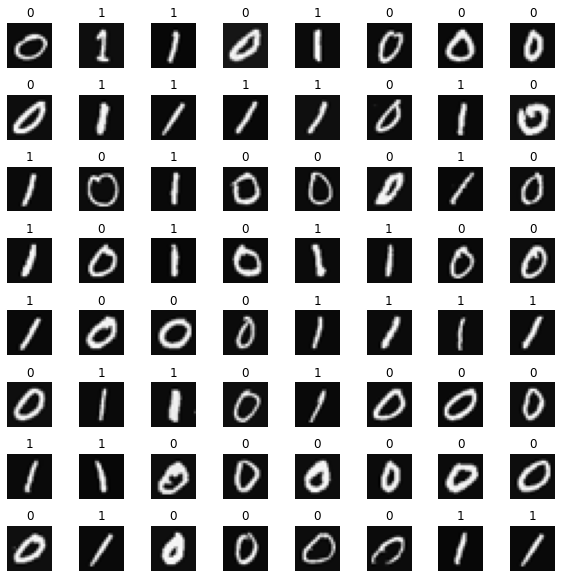

In [15]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1)

for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Display the label above the image
    ax.set_title(y[random_index,0])
    ax.set_axis_off()

<a name="2.3"></a>
### 2.3 Model representation（模型表示）

The neural network you will use in this assignment is shown in the figure below. 
在这个任务中，您将使用的神经网络如下图所示。

- This has three dense layers with sigmoid activations.
- 它包含三个具有sigmoid激活函数的全连接（dense）层。
    - Recall that our inputs are pixel values of digit images.
    - 请注意，我们的输入是数字图像的像素值。
    - Since the images are of size $20\times20$, this gives us $400$ inputs  
    - 由于图像的大小为 $20\times20$，因此我们得到 $400$ 个输入
    
<img src="images/C2_W1_Assign1.PNG" width="500" height="400">

- The parameters have dimensions that are sized for a neural network with $25$ units in layer 1, $15$ units in layer 2 and $1$ output unit in layer 3. 

- 第一层神经网络具有$25$ 个神经元，第二层神经网络具有$15$个神经元，第三次神经网络有$1$个神经元。

   - Recall that the dimensions of these parameters are determined as follows:
   - 请注意，这些参数的维度确定如下：
      - If network has $s_{in}$ units in a layer and $s_{out}$ units in the next layer, then
      - 如果网络的第一层有$s_{in}$个神经元，在下一层有$s_{out}$个神经元
          - $W$ will be of dimension $s_{in} \times s_{out}$.
          - $W$ 的维度将是$s_{in} \times s_{out}$。
          - $b$ will a vector with $s_{out}$ elements
          - $b$ 将是一个具有$s_{out}$ 个元素的向量
   - Therefore, the shapes of `W`, and `b`,  are 
   - 因此，`W` 和 `b` 的形状是 
        - layer1: The shape of `W1` is (400, 25) and the shape of `b1` is (25,)
        - 第一层：`W1` 的形状是(400, 25)，`b1` 的形状是(25,)
        - layer2: The shape of `W2` is (25, 15) and the shape of `b2` is: (15,)
        - 第二层：`W2` 的形状是(25, 15)，`b2` 的形状是(15,)
        - layer3: The shape of `W3` is (15, 1) and the shape of `b3` is: (1,)
        - 第三层：`W3` 的形状是(15, 1)，`b3` 的形状是(1,)
        
>**Note:** The bias vector `b` could be represented as a 1-D (n,) or 2-D (n,1) array. Tensorflow utilizes a 1-D representation and this lab will maintain that convention. 

>**Note:** 偏置向量 `b` 可以表示为1维（n,）或2维（n,1）数组。TensorFlow使用1维表示，本实验将保持这一约定。

<a name="2.4"></a>
### 2.4 Tensorflow Model Implementation


Tensorflow models are built layer by layer. A layer's input dimensions ($s_{in}$ above) are calculated for you. You specify a layer's *output dimensions* and this determines the next layer's input dimension. The input dimension of the first layer is derived from the size of the input data specified in the `model.fit` statment below. 

TensorFlow模型是逐层构建的。第一层的输入维度（上面提到的 $s_{in}$）是为你计算好的。指定第一层的输出维度，这决定了下一层的*输入维度*。
第一层的输入维度是从`model.fit`语句中指定的输入数据大小中得出的。


>**Note:** It is also possible to add an input layer that specifies the input dimension of the first layer. For example:  
`tf.keras.Input(shape=(400,)),    #specify input shape`  
We will include that here to illuminate some model sizing.

>**注意:**  还可以添加一个输入层来指定第一层的输入维度。例如：
`tf.keras.Input(shape=(400,)), #指定输入形状`
我们在这里包含这一点，以阐明一些模型尺寸的问题。

<a name="ex01"></a>
### Exercise 1

Below, using Keras [Sequential model](https://keras.io/guides/sequential_model/) and [Dense Layer](https://keras.io/api/layers/core_layers/dense/) with a sigmoid activation to construct the network described above.

下面，使用Keras的Sequential模型和Dense层，并配置一个sigmoid激活函数来构建上述描述的网络。

In [35]:
# UNQ_C1
# GRADED CELL: Sequential model

model = Sequential(
    [               
        tf.keras.Input(shape=(400,)),    #specify input size
        ### START CODE HERE ### 
        Dense(25, activation="sigmoid"),
        Dense(15, activation="sigmoid"),
        Dense(1, activation="sigmoid")
        ### END CODE HERE ### 
    ], name = "my_model" 
)                            

In [19]:
model.summary()

Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense_3 (Dense)              (None, 25)                10025     
_________________________________________________________________
dense_4 (Dense)              (None, 15)                390       
_________________________________________________________________
dense_5 (Dense)              (None, 1)                 16        
Total params: 10,431
Trainable params: 10,431
Non-trainable params: 0
_________________________________________________________________


<details>
  <summary><font size="3" color="darkgreen"><b>Expected Output (Click to Expand) </b></font></summary>
The `model.summary()` function displays a useful summary of the model. Because we have specified an input layer size, the shape of the weight and bias arrays are determined and the total number of parameters per layer can be shown. Note, the names of the layers may vary as they are auto-generated.  
    
    
```
Model: "my_model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
=================================================================
dense (Dense)                (None, 25)                10025     
_________________________________________________________________
dense_1 (Dense)              (None, 15)                390       
_________________________________________________________________
dense_2 (Dense)              (None, 1)                 16        
=================================================================
Total params: 10,431
Trainable params: 10,431
Non-trainable params: 0
_________________________________________________________________
```

<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
As described in the lecture:
    
```python
model = Sequential(                      
    [                                   
        tf.keras.Input(shape=(400,)),    # specify input size (optional)
        Dense(25, activation='sigmoid'), 
        Dense(15, activation='sigmoid'), 
        Dense(1,  activation='sigmoid')  
    ], name = "my_model"                                    
)                                       
``` 

In [20]:
# UNIT TESTS
from public_tests import * 

test_c1(model)

All tests passed!


The parameter counts shown in the summary correspond to the number of elements in the weight and bias arrays as shown below.

摘要中显示的参数数量对应于权重和偏置数组中元素的数量，如下所示。

In [21]:
L1_num_params = 400 * 25 + 25  # W1 parameters  + b1 parameters
L2_num_params = 25 * 15 + 15   # W2 parameters  + b2 parameters
L3_num_params = 15 * 1 + 1     # W3 parameters  + b3 parameters
print("L1 params = ", L1_num_params, ", L2 params = ", L2_num_params, ",  L3 params = ", L3_num_params )

L1 params =  10025 , L2 params =  390 ,  L3 params =  16


Let's further examine the weights to verify that tensorflow produced the same dimensions as we calculated above.

让我们进一步检查权重，以验证TensorFlow生成的维度是否与我们之前计算的一致。

In [22]:
[layer1, layer2, layer3] = model.layers

In [23]:
#### Examine Weights shapes
W1,b1 = layer1.get_weights()
W2,b2 = layer2.get_weights()
W3,b3 = layer3.get_weights()
print(f"W1 shape = {W1.shape}, b1 shape = {b1.shape}")
print(f"W2 shape = {W2.shape}, b2 shape = {b2.shape}")
print(f"W3 shape = {W3.shape}, b3 shape = {b3.shape}")

W1 shape = (400, 25), b1 shape = (25,)
W2 shape = (25, 15), b2 shape = (15,)
W3 shape = (15, 1), b3 shape = (1,)


**Expected Output**
```
W1 shape = (400, 25), b1 shape = (25,)  
W2 shape = (25, 15), b2 shape = (15,)  
W3 shape = (15, 1), b3 shape = (1,)
```

`xx.get_weights` returns a NumPy array. One can also access the weights directly in their tensor form. Note the shape of the tensors in the final layer.

`xx.get_weights` 方法返回一个NumPy数组。人们也可以直接以张量的形式访问权重。请注意最后一层中张量的形状。

In [24]:
print(model.layers[2].weights)

[<tf.Variable 'dense_5/kernel:0' shape=(15, 1) dtype=float32, numpy=
array([[-0.59518],
       [ 0.28978],
       [ 0.45733],
       [-0.53707],
       [ 0.31016],
       [ 0.33991],
       [ 0.33034],
       [ 0.23052],
       [ 0.07301],
       [ 0.43694],
       [ 0.22259],
       [-0.0363 ],
       [-0.08616],
       [-0.19921],
       [ 0.38406]], dtype=float32)>, <tf.Variable 'dense_5/bias:0' shape=(1,) dtype=float32, numpy=array([0.], dtype=float32)>]


The following code will define a loss function and run gradient descent to fit the weights of the model to the training data. This will be explained in more detail in the following week.

以下代码将定义一个损失函数，并运行梯度下降来使模型的权重与训练数据相匹配（）。这将在下周进行更详细的解释。

In [25]:
model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(0.001),
)

model.fit(
    X,y,
    epochs=20
)

2024-11-16 22:18:21.076911: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


Epoch 1/20
32/32 [==============================] - 1s 3ms/step - loss: 0.6456
Epoch 2/20
32/32 [==============================] - 0s 3ms/step - loss: 0.5035
Epoch 3/20
32/32 [==============================] - 0s 3ms/step - loss: 0.3630
Epoch 4/20
32/32 [==============================] - 0s 3ms/step - loss: 0.2529
Epoch 5/20
32/32 [==============================] - 0s 3ms/step - loss: 0.1834
Epoch 6/20
32/32 [==============================] - 0s 3ms/step - loss: 0.1404
Epoch 7/20
32/32 [==============================] - 0s 3ms/step - loss: 0.1123
Epoch 8/20
32/32 [==============================] - 0s 3ms/step - loss: 0.0930
Epoch 9/20
32/32 [==============================] - 0s 3ms/step - loss: 0.0787
Epoch 10/20
32/32 [==============================] - 0s 3ms/step - loss: 0.0680
Epoch 11/20
32/32 [==============================] - 0s 3ms/step - loss: 0.0596
Epoch 12/20
32/32 [==============================] - 0s 3ms/step - loss: 0.0528
Epoch 13/20
32/32 [==============================

To run the model on an example to make a prediction, use [Keras `predict`](https://www.tensorflow.org/api_docs/python/tf/keras/Model). The input to `predict` is an array so the single example is reshaped to be two dimensional.

要在示例上运行模型以进行预测，请使用Keras的predict函数。predict函数的输入是一个数组，因此单个示例需要被重新转换为二维的。

In [26]:
prediction = model.predict(X[0].reshape(1,400))  # a zero
print(f" predicting a zero: {prediction}")
prediction = model.predict(X[500].reshape(1,400))  # a one
print(f" predicting a one:  {prediction}")

 predicting a zero: [[0.03119]]
 predicting a one:  [[0.9892]]


The output of the model is interpreted as a probability. In the first example above, the input is a zero. The model predicts the probability that the input is a one is nearly zero. 

模型的输出被解释为概率。在上面的第一个示例中，输入是0，模型预测输入为1的概率几乎为0。


In the second example, the input is a one. The model predicts the probability that the input is a one is nearly one.
As in the case of logistic regression, the probability is compared to a threshold to make a final prediction.

在第二个示例中，输入是1，模型预测输入为1的概率几乎为1。
与逻辑回归的情况一样，将这个概率与一个阈值进行比较，以做出最终预测。

In [27]:
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print(f"prediction after threshold: {yhat}")

prediction after threshold: 1


Let's compare the predictions vs the labels for a random sample of 64 digits. This takes a moment to run.

让我们比较一下64个随机数字样本的预测结果与标签。这需要一点时间来运行。

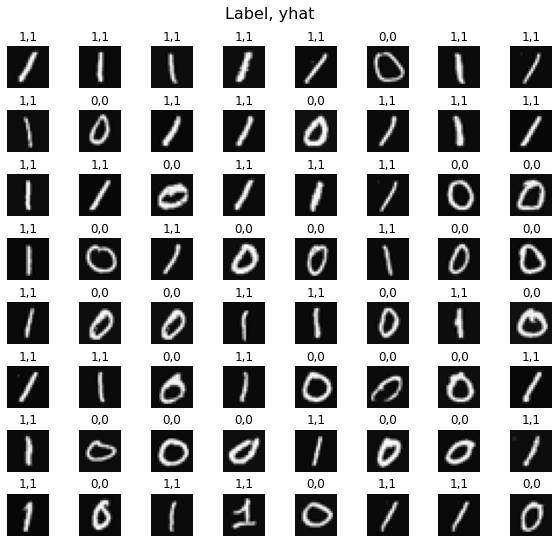

In [28]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
    
    # Predict using the Neural Network
    prediction = model.predict(X[random_index].reshape(1,400))
    if prediction >= 0.5:
        yhat = 1
    else:
        yhat = 0
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{yhat}")
    ax.set_axis_off()
fig.suptitle("Label, yhat", fontsize=16)
plt.show()

<a name="2.5"></a>
### 2.5 NumPy Model Implementation (Forward Prop in NumPy)  NumPy模型实现（NumPy中的前向传播）


As described in lecture, it is possible to build your own dense layer using NumPy. This can then be utilized to build a multi-layer neural network. 

正如课程中所述，您可以使用NumPy构建自己的全连接层（Dense层）。然后，可以利用它来构建多层神经网络。

<img src="images/C2_W1_dense2.PNG" width="600" height="450">


<a name="ex02"></a>
### Exercise 2

Below, build a dense layer subroutine. The example in lecture utilized a for loop to visit each unit (`j`) in the layer and perform the dot product of the weights for that unit (`W[:,j]`) and sum the bias for the unit (`b[j]`) to form `z`. An activation function `g(z)` is then applied to that result. This section will not utilize some of the matrix operations described in the optional lectures. These will be explored in a later section.


下面，我们将构建一个全连接层（Dense层）的子程序。课程中的示例使用了一个for循环来遍历该层中的每个单元（`j`），并计算该单元的权重（`W[:,j]`）的点积，同时加上该单元的偏置（`b[j]`）来形成`z`。然后，对结果应用激活函数`g(z)` 。本节不会使用可选讲座中描述的一些矩阵运算。这些将在后面的部分中探讨。

In [30]:
# UNQ_C2
# GRADED FUNCTION: my_dense

def my_dense(a_in, W, b, g):
    """
    Computes dense layer
    Args:
      a_in (ndarray (n, )) : Data, 1 example 
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j, )) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      a_out (ndarray (j,))  : j units
    """
    units = W.shape[1]
    a_out = np.zeros(units)
    ### START CODE HERE ### 
    for i in range(units):
        w = W[:,i]
        z=np.dot(w,a_in) + b[i]
        a_out[i]=g(z)
    ### END CODE HERE ### 
    return(a_out)


In [23]:
# Quick Check
x_tst = 0.1*np.arange(1,3,1).reshape(2,)  # (1 examples, 2 features)
W_tst = 0.1*np.arange(1,7,1).reshape(2,3) # (2 input features, 3 output features)
b_tst = 0.1*np.arange(1,4,1).reshape(3,)  # (3 features)
A_tst = my_dense(x_tst, W_tst, b_tst, sigmoid)
print(A_tst)

[0.54735762 0.57932425 0.61063923]


**Expected Output**
```
[0.54735762 0.57932425 0.61063923]
```

<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
As described in the lecture:
    
```python
def my_dense(a_in, W, b, g):
    """
    Computes dense layer
    Args:
      a_in (ndarray (n, )) : Data, 1 example 
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j, )) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      a_out (ndarray (j,))  : j units
    """
    units = W.shape[1]
    a_out = np.zeros(units)
    for j in range(units):             
        w =                            # Select weights for unit j. These are in column j of W
        z =                            # dot product of w and a_in + b
        a_out[j] =                     # apply activation to z
    return(a_out)
```
   
    
<details>
  <summary><font size="3" color="darkgreen"><b>Click for more hints</b></font></summary>

    
```python
def my_dense(a_in, W, b, g):
    """
    Computes dense layer
    Args:
      a_in (ndarray (n, )) : Data, 1 example 
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j, )) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      a_out (ndarray (j,))  : j units
    """
    units = W.shape[1]
    a_out = np.zeros(units)
    for j in range(units):             
        w = W[:,j]                     
        z = np.dot(w, a_in) + b[j]     
        a_out[j] = g(z)                
    return(a_out)
``` 

In [24]:
# UNIT TESTS
test_c2(my_dense)

All tests passed!


The following cell builds a three-layer neural network utilizing the `my_dense` subroutine above.

下面的单元格利用上面定义的 `my_dense` 子程序构建了一个三层神经网络。

In [25]:
def my_sequential(x, W1, b1, W2, b2, W3, b3):
    a1 = my_dense(x,  W1, b1, sigmoid)
    a2 = my_dense(a1, W2, b2, sigmoid)
    a3 = my_dense(a2, W3, b3, sigmoid)
    return(a3)

We can copy trained weights and biases from Tensorflow.

我们可以从TensorFlow中复制训练好的权重和偏置。

In [26]:
W1_tmp,b1_tmp = layer1.get_weights()
W2_tmp,b2_tmp = layer2.get_weights()
W3_tmp,b3_tmp = layer3.get_weights()

In [27]:
# make predictions
prediction = my_sequential(X[0], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print( "yhat = ", yhat, " label= ", y[0,0])
prediction = my_sequential(X[500], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
if prediction >= 0.5:
    yhat = 1
else:
    yhat = 0
print( "yhat = ", yhat, " label= ", y[500,0])

yhat =  0  label=  0
yhat =  1  label=  1


Run the following cell to see predictions from both the Numpy model and the Tensorflow model. This takes a moment to run.

运行下面的单元格，以查看来自NumPy模型和TensorFlow模型的预测。这需要一点时间来运行。

---

### NumPy 2.x 兼容：布尔数组不能直接转成 int

下面这格保留了原教材的 NumPy 1.x 写法：`int(my_prediction >= 0.5)` 以及 `int(tf_prediction >= 0.5)`。新版 NumPy 对非零维数组的隐式标量转换更严格。若报 `TypeError: only 0-dimensional arrays can be converted to Python scalars`，请**跳过原图像可视化格**，然后取消后一格代码的注释并运行。新例使用 `np.asarray(...).item()`，仅适用于每次预测恰好只有一个元素的情况。


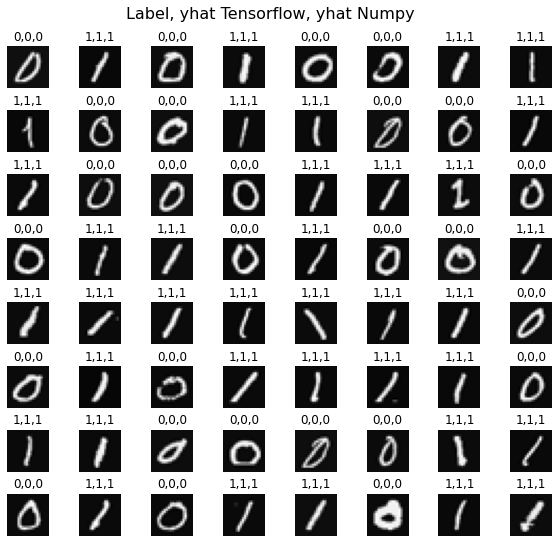

In [28]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8,8, figsize=(8,8))
fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

for i,ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20,20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')

    # Predict using the Neural Network implemented in Numpy
    my_prediction = my_sequential(X[random_index], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
    my_yhat = int(my_prediction >= 0.5)

    # Predict using the Neural Network implemented in Tensorflow
    tf_prediction = model.predict(X[random_index].reshape(1,400))
    tf_yhat = int(tf_prediction >= 0.5)
    
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]},{tf_yhat},{my_yhat}")
    ax.set_axis_off() 
fig.suptitle("Label, yhat Tensorflow, yhat Numpy", fontsize=16)
plt.show()

In [ ]:
# NumPy 2.x 可选完整替代：取消注释运行；前面训练、权重准备单元格须已执行
# import warnings
# warnings.simplefilter(action='ignore', category=FutureWarning)
# # You do not need to modify anything in this cell

# m, n = X.shape

# fig, axes = plt.subplots(8,8, figsize=(8,8))
# fig.tight_layout(pad=0.1,rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

# for i,ax in enumerate(axes.flat):
#     # Select random indices
#     random_index = np.random.randint(m)

#     # Select rows corresponding to the random indices and
#     # reshape the image
#     X_random_reshaped = X[random_index].reshape((20,20)).T

#     # Display the image
#     ax.imshow(X_random_reshaped, cmap='gray')

#     # Predict using the Neural Network implemented in Numpy
#     my_prediction = my_sequential(X[random_index], W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
#     my_yhat = int(np.asarray(my_prediction >= 0.5).item())

#     # Predict using the Neural Network implemented in Tensorflow
#     tf_prediction = model.predict(X[random_index].reshape(1,400))
#     tf_yhat = int(np.asarray(tf_prediction >= 0.5).item())

#     # Display the label above the image
#     ax.set_title(f"{y[random_index,0]},{tf_yhat},{my_yhat}")
#     ax.set_axis_off() 
# fig.suptitle("Label, yhat Tensorflow, yhat Numpy", fontsize=16)
# plt.show()


<a name="2.6"></a>
### 2.6 Vectorized NumPy Model Implementation (Optional)  向量化NumPy模型实现（可选）
The optional lectures described vector and matrix operations that can be used to speed the calculations.
Below describes a layer operation that computes the output for all units in a layer on a given input example:

可选讲座中描述了可用于加速计算的向量和矩阵运算。
下面描述了一个层操作，该操作计算给定输入示例中层中所有单元的输出：

<img src="images/C2_W1_VectorMatrix.PNG" width="600" height="450">

We can demonstrate this using the examples `X` and the `W1`,`b1` parameters above. We use `np.matmul` to perform the matrix multiply. Note, the dimensions of x and W must be compatible as shown in the diagram above.


我们可以使用上面的示例 `X` 以及`W1`、`b1`参数来演示这一点。我们使用`np.matmul`来执行矩阵乘法。请注意，如上图所示，x和W的维度必须兼容。


In [29]:
x = X[0].reshape(-1,1)         # column vector (400,1)
z1 = np.matmul(x.T,W1) + b1    # (1,400)(400,25) = (1,25)
a1 = sigmoid(z1)
print(a1.shape)

(1, 25)


You can take this a step further and compute all the units for all examples in one Matrix-Matrix operation.

你可以更进一步，通过一次矩阵-矩阵运算来计算所有示例中所有单元的输出。

<img src="images/C2_W1_MatrixMatrix.PNG" width="600" height="450">
The full operation is $\mathbf{Z}=\mathbf{XW}+\mathbf{b}$. This will utilize NumPy broadcasting to expand $\mathbf{b}$ to $m$ rows. If this is unfamiliar, a short tutorial is provided at the end of the notebook.

完整的运算是Z=XW+b。这将利用NumPy的广播机制将b扩展到m行。如果你对此不熟悉，笔记本（notebook）的末尾提供了一个简短的教程。

<a name="ex03"></a>
### Exercise 3

Below, compose a new `my_dense_v` subroutine that performs the layer calculations for a matrix of examples. This will utilize `np.matmul()`.

下面，编写一个新的 `my_dense_v` 子程序，该子程序对示例矩阵执行层的计算。这将使用 `np.matmul()`。

In [31]:
# UNQ_C3
# GRADED FUNCTION: my_dense_v

def my_dense_v(A_in, W, b, g):
    """
    Computes dense layer
    Args:
      A_in (ndarray (m,n)) : Data, m examples, n features each
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (1,j)) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      A_out (ndarray (m,j)) : m examples, j units
    """
### START CODE HERE ### 
    A_out = g(np.matmul(A_in,W) + b)
    
### END CODE HERE ### 
    return(A_out)

In [32]:
X_tst = 0.1*np.arange(1,9,1).reshape(4,2) # (4 examples, 2 features)
W_tst = 0.1*np.arange(1,7,1).reshape(2,3) # (2 input features, 3 output features)
b_tst = 0.1*np.arange(1,4,1).reshape(1,3) # (1, 3 features)
A_tst = my_dense_v(X_tst, W_tst, b_tst, sigmoid)
print(A_tst)

tf.Tensor(
[[0.54735762 0.57932425 0.61063923]
 [0.57199613 0.61301418 0.65248946]
 [0.5962827  0.64565631 0.6921095 ]
 [0.62010643 0.67699586 0.72908792]], shape=(4, 3), dtype=float64)


**Expected Output**

```
[[0.54735762 0.57932425 0.61063923]
 [0.57199613 0.61301418 0.65248946]
 [0.5962827  0.64565631 0.6921095 ]
 [0.62010643 0.67699586 0.72908792]]
 ```

<details>
  <summary><font size="3" color="darkgreen"><b>Click for hints</b></font></summary>
    In matrix form, this can be written in one or two lines. 
    
       Z = np.matmul of A_in and W plus b    
       A_out is g(Z)  
<details>
  <summary><font size="3" color="darkgreen"><b>Click for code</b></font></summary>

```python
def my_dense_v(A_in, W, b, g):
    """
    Computes dense layer
    Args:
      A_in (ndarray (m,n)) : Data, m examples, n features each
      W    (ndarray (n,j)) : Weight matrix, n features per unit, j units
      b    (ndarray (j,1)) : bias vector, j units  
      g    activation function (e.g. sigmoid, relu..)
    Returns
      A_out (ndarray (m,j)) : m examples, j units
    """
    Z = np.matmul(A_in,W) + b    
    A_out = g(Z)                 
    return(A_out)
```


In [33]:
# UNIT TESTS
test_c3(my_dense_v)

All tests passed!


The following cell builds a three-layer neural network utilizing the `my_dense_v` subroutine above.

下面的单元格利用上面定义的 `my_dense_v` 子程序构建了一个三层神经网络。

In [34]:
def my_sequential_v(X, W1, b1, W2, b2, W3, b3):
    A1 = my_dense_v(X,  W1, b1, sigmoid)
    A2 = my_dense_v(A1, W2, b2, sigmoid)
    A3 = my_dense_v(A2, W3, b3, sigmoid)
    return(A3)

We can again copy trained weights and biases from Tensorflow.

我们可以再次从TensorFlow中复制训练好的权重和偏置。

In [35]:
W1_tmp,b1_tmp = layer1.get_weights()
W2_tmp,b2_tmp = layer2.get_weights()
W3_tmp,b3_tmp = layer3.get_weights()

Let's make a prediction with the new model. This will make a prediction on *all of the examples at once*. Note the shape of the output.

让我们用新模型进行预测。这将一次性对所有示例进行预测。请注意输出的形状。

In [36]:
Prediction = my_sequential_v(X, W1_tmp, b1_tmp, W2_tmp, b2_tmp, W3_tmp, b3_tmp )
Prediction.shape

TensorShape([1000, 1])

We'll apply a threshold of 0.5 as before, but to all predictions at once.

我们将像之前一样应用0.5的阈值，但这次是一次性对所有预测应用。

In [37]:
Yhat = (Prediction >= 0.5).numpy().astype(int)
print("predict a zero: ",Yhat[0], "predict a one: ", Yhat[500])

predict a zero:  [0] predict a one:  [1]


Run the following cell to see predictions. This will use the predictions we just calculated above. This takes a moment to run.

运行下面的单元格以查看预测结果。这将使用我们上面刚刚计算出的预测结果。这需要一点时间来运行。

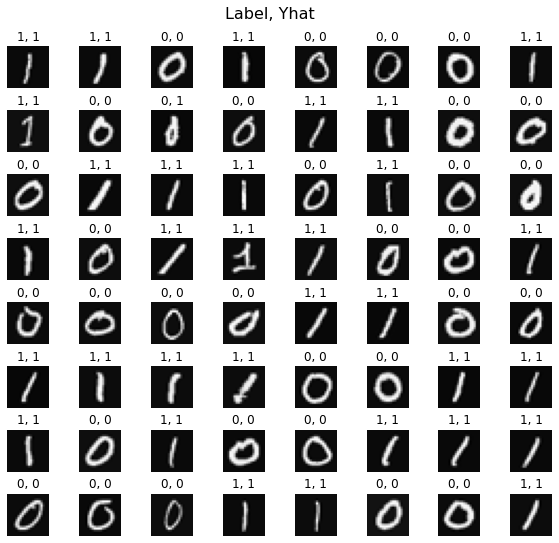

In [38]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
# You do not need to modify anything in this cell

m, n = X.shape

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
fig.tight_layout(pad=0.1, rect=[0, 0.03, 1, 0.92]) #[left, bottom, right, top]

for i, ax in enumerate(axes.flat):
    # Select random indices
    random_index = np.random.randint(m)
    
    # Select rows corresponding to the random indices and
    # reshape the image
    X_random_reshaped = X[random_index].reshape((20, 20)).T
    
    # Display the image
    ax.imshow(X_random_reshaped, cmap='gray')
   
    # Display the label above the image
    ax.set_title(f"{y[random_index,0]}, {Yhat[random_index, 0]}")
    ax.set_axis_off() 
fig.suptitle("Label, Yhat", fontsize=16)
plt.show()

You can see how one of the misclassified images looks.

你可以看到其中一个被错误分类的图像的样子。

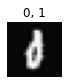

In [39]:
fig = plt.figure(figsize=(1, 1))
errors = np.where(y != Yhat)
random_index = errors[0][0]
X_random_reshaped = X[random_index].reshape((20, 20)).T
plt.imshow(X_random_reshaped, cmap='gray')
plt.title(f"{y[random_index,0]}, {Yhat[random_index, 0]}")
plt.axis('off')
plt.show()

<a name="2.7"></a>
### 2.7 Congratulations!
You have successfully built and utilized a neural network.

你已经成功构建并使用了神经网络。

<a name="2.8"></a>
### 2.8 NumPy Broadcasting Tutorial (Optional)


In the last example,  $\mathbf{Z}=\mathbf{XW} + \mathbf{b}$ utilized NumPy broadcasting to expand the vector $\mathbf{b}$. If you are not familiar with NumPy Broadcasting, this short tutorial is provided.


在最后一个示例中，$\mathbf{Z}=\mathbf{XW} + \mathbf{b}$ 利用了NumPy的广播机制来扩展向量$\mathbf{b}$。如果你不熟悉NumPy的广播机制，这里提供一个简短的教程。

$\mathbf{XW}$  is a matrix-matrix operation with dimensions $(m,j_1)(j_1,j_2)$ which results in a matrix with dimension  $(m,j_2)$. To that, we add a vector $\mathbf{b}$ with dimension $(1,j_2)$.  $\mathbf{b}$ must be expanded to be a $(m,j_2)$ matrix for this element-wise operation to make sense. This expansion is accomplished for you by NumPy broadcasting.

$\mathbf{XW}$ 是一个矩阵-矩阵运算，其维度为$(m,j_1)(j_1,j_2)$ ，结果是一个维度为$(m,j_2)$的矩阵。我们向这个结果中加上一个维度为$(1,j_2)$ 的向量$\mathbf{b}$ 。为了使这个逐元素运算有意义，$\mathbf{b}$ 必须被扩展为一个$(m,j_2)$ 的矩阵。这个扩展是由NumPy的广播机制为你完成的。




<figure>
    <center> <img src="./images/C2_W1_Assign1_BroadcastIndexes.PNG"  alt='missing' width="400"  ><center/>
    <figcaption>Calculating Broadcast Result shape</figcaption>
<figure/>
        
        计算广播结果的形状

The graphic below describes expanding dimensions. Note the red text below:

下面的图形描述了维度的扩展。请注意下面的红色文字：

<figure>
    <center> <img src="./images/C2_W1_Assign1_Broadcasting.gif"  alt='missing' width="600"  ><center/>
    <figcaption>Broadcast notionally expands arguments to match for element wise operations</figcaption>
<figure/>
        
        
        广播机制在概念上会扩展参数以匹配逐元素运算

Broadcasting applies to element-wise operations.  
Its basic operation is to 'stretch' a smaller dimension by replicating elements to match a larger dimension.

广播机制适用于逐元素运算。
其基本操作是通过复制元素来“拉伸”较小的维度，以匹配较大的维度。


More [specifically](https://NumPy.org/doc/stable/user/basics.broadcasting.html): 更具体地说：

When operating on two arrays, NumPy compares their shapes element-wise. It starts with the trailing (i.e. rightmost) dimensions and works its way left. Two dimensions are compatible when

在对两个数组进行操作时，NumPy会逐元素地比较它们的形状。它从尾部（即最右边的）维度开始，向左进行。当满足以下条件时，两个维度是兼容的：
- they are equal, or
- one of them is 1  

- 它们相等，或者
- 其中之一为1

If these conditions are not met, a ValueError: operands could not be broadcast together exception is thrown, indicating that the arrays have incompatible shapes. The size of the resulting array is the size that is not 1 along each axis of the inputs.

如果不满足这些条件，则会抛出ValueError: operands could not be broadcast together异常，表明数组的形状不兼容。结果数组的大小是输入数组在每个轴上不为1的大小。

Here are some examples:

以下是一些示例：

The graphic above shows NumPy expanding the arguments to match before the final operation. Note that this is a notional description. The actual mechanics of NumPy operation choose the most efficient implementation.

上面的图形展示了NumPy在最终操作之前将参数扩展以匹配的过程。请注意，这是一个概念性的描述。NumPy操作的实际机制会选择最有效的实现方式。

For each of the following examples, try to guess the size of the result before running the example.

对于以下每个示例，请尝试在运行示例之前猜测结果的大小。

In [40]:
a = np.array([1,2,3]).reshape(-1,1)  #(3,1)
b = 5
print(f"(a + b).shape: {(a + b).shape}, \na + b = \n{a + b}")

(a + b).shape: (3, 1), 
a + b = 
[[6]
 [7]
 [8]]


Note that this applies to all element-wise operations:

请注意，这适用于所有逐元素运算：

In [41]:
a = np.array([1,2,3]).reshape(-1,1)  #(3,1)
b = 5
print(f"(a * b).shape: {(a * b).shape}, \na * b = \n{a * b}")

(a * b).shape: (3, 1), 
a * b = 
[[ 5]
 [10]
 [15]]


<figure>
    <img src="./images/C2_W1_Assign1_VectorAdd.PNG"  alt='missing' width="740" >
    <center><figcaption><b>Row-Column Element-Wise Operations</b></figcaption></center>
<figure/>

In [42]:
a = np.array([1,2,3,4]).reshape(-1,1)
b = np.array([1,2,3]).reshape(1,-1)
print(a)
print(b)
print(f"(a + b).shape: {(a + b).shape}, \na + b = \n{a + b}")

[[1]
 [2]
 [3]
 [4]]
[[1 2 3]]
(a + b).shape: (4, 3), 
a + b = 
[[2 3 4]
 [3 4 5]
 [4 5 6]
 [5 6 7]]


This is the scenario in the dense layer you built above. Adding a 1-D vector $b$ to a (m,j) matrix.

这正是你在上面构建的密集层中的场景。将一个1维向量 $b$ 加到一个(m,j)矩阵上。
<figure>
    <img src="./images/C2_W1_Assign1_BroadcastMatrix.PNG"  alt='missing' width="740" >
    <center><figcaption><b>Matrix + 1-D Vector</b></figcaption></center>
<figure/>